# Time series forecast para el mercado de vivienda nueva en Colombia

In [20]:
#Usaremos las siguientes librerías de R
library("forecast")
library("tseries")
library("readxl")
library("tsoutliers")

In [21]:
#Lectura de datos
ventas<-read_xlsx('Time-series-datos.xlsx')

In [22]:
head(ventas)

Fecha,Y- Unidades de vivienda vendidas,X-Tasa de desempleo,X-IPC Variación porcentual mensual,X - Adquisición de vivienda no VIS. Tasa de interés promedio,X - Adquisición de vivienda VIS. Tasa de interés promedio,X-ICCV variación porcentual mensual e ICOCED,X-Índice de Confianza del Consumidor,Crisis Mi Casa Ya
<dttm>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2010-01-01,8758,14.88,0.69,13.70,13.04,0.58,7.1,0
2010-02-01,9751,12.69,0.83,13.70,12.92,0.35,11.5,0
2010-03-01,10226,11.96,0.25,13.66,12.94,0.46,16.1,0
2010-04-01,8759,12.44,0.46,13.62,12.78,0.44,19.3,0
2010-05-01,8771,12.26,0.10,13.37,12.76,0.53,22.5,0
2010-06-01,9044,11.98,0.11,13.05,12.59,0.25,27.2,0


## Estadística descriptiva

In [23]:
#Construcción de los objetos tipo serie de tiempo
ventas_vivienda<-ts(ventas$`Y- Unidades de vivienda vendidas`, start = c(2010,1), end=c(2025,10), frequency = 12)

In [24]:
#Debemos hacer una división en train y test, train hasta julio de 2022 y test de agosto de 2022 en adelante
ventas_vivienda.train <- window(ventas_vivienda, start=c(2010, 1), end=c(2022, 7))
ventas_vivienda.test <- window(ventas_vivienda, start=c(2022, 8), end=c(2025, 10))

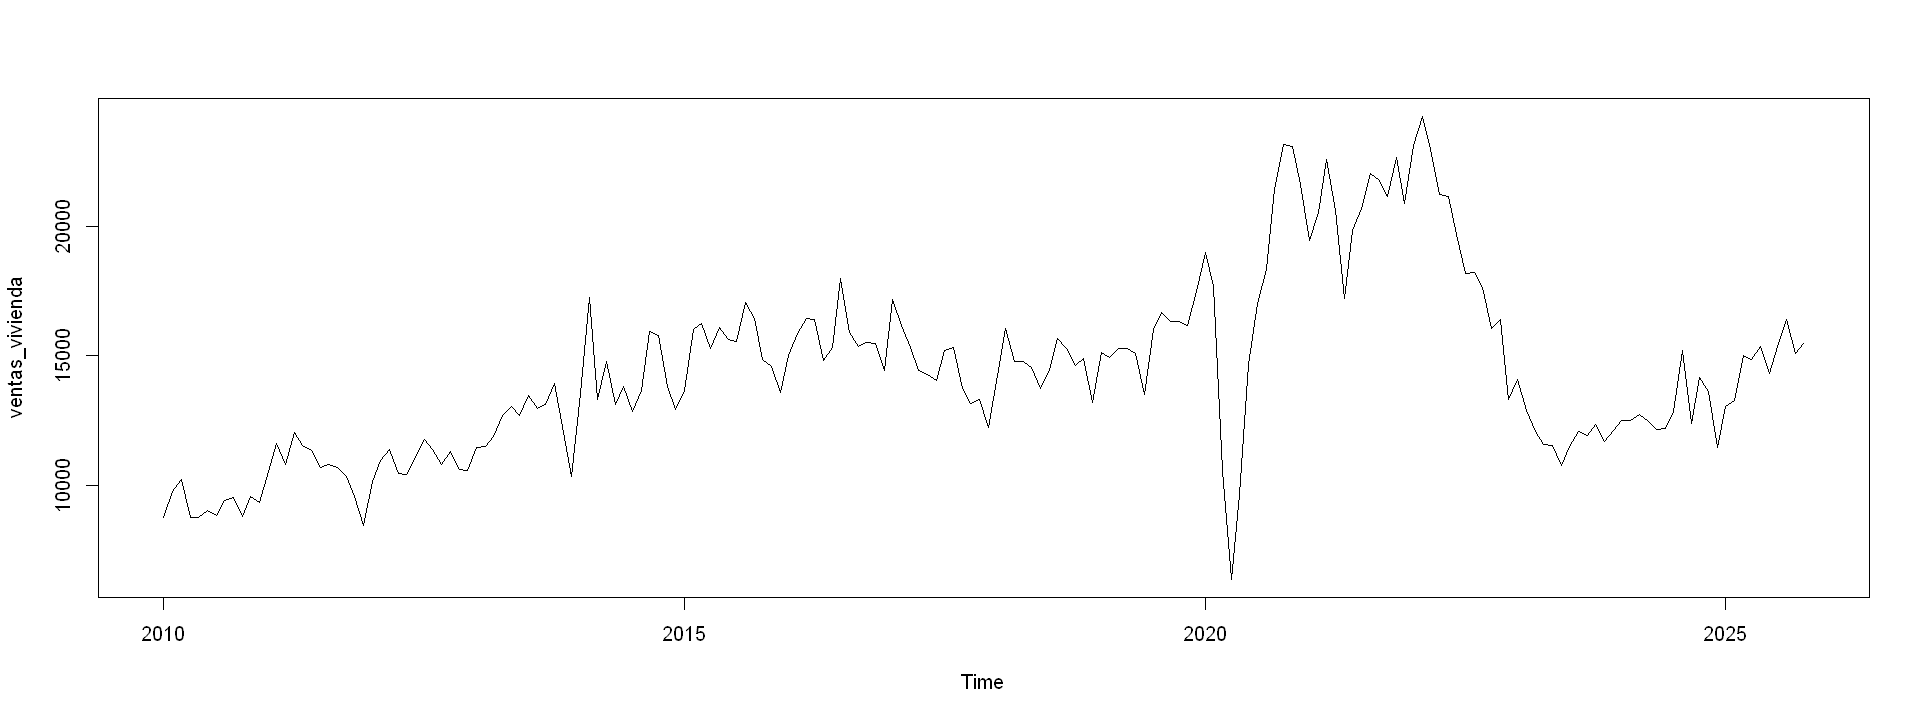

In [25]:
#Gráfica de la serie de tiempo
options(repr.plot.width = 16, repr.plot.height = 6)
plot(ventas_vivienda)

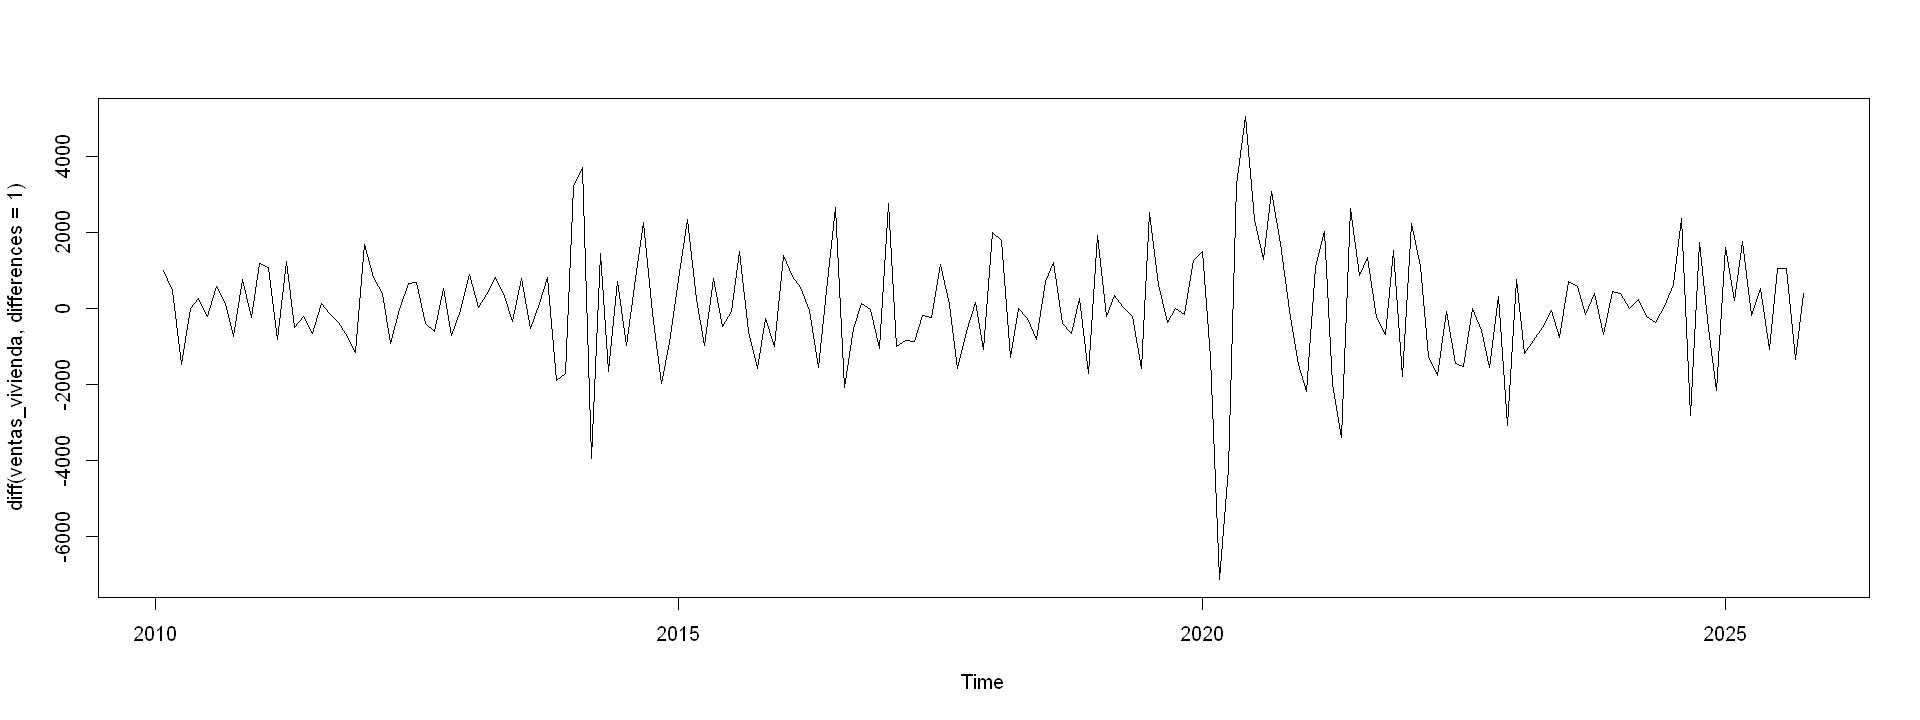

In [26]:
# Se ve que hay una tendencia al crecimiento de las ventas, se ven también unos atípicos clarísimos en la pandemia 
# También se ve un bajón marcado en las ventas durante los últimos 3 años

#términos diferenciados
plot(diff(ventas_vivienda, differences=1))

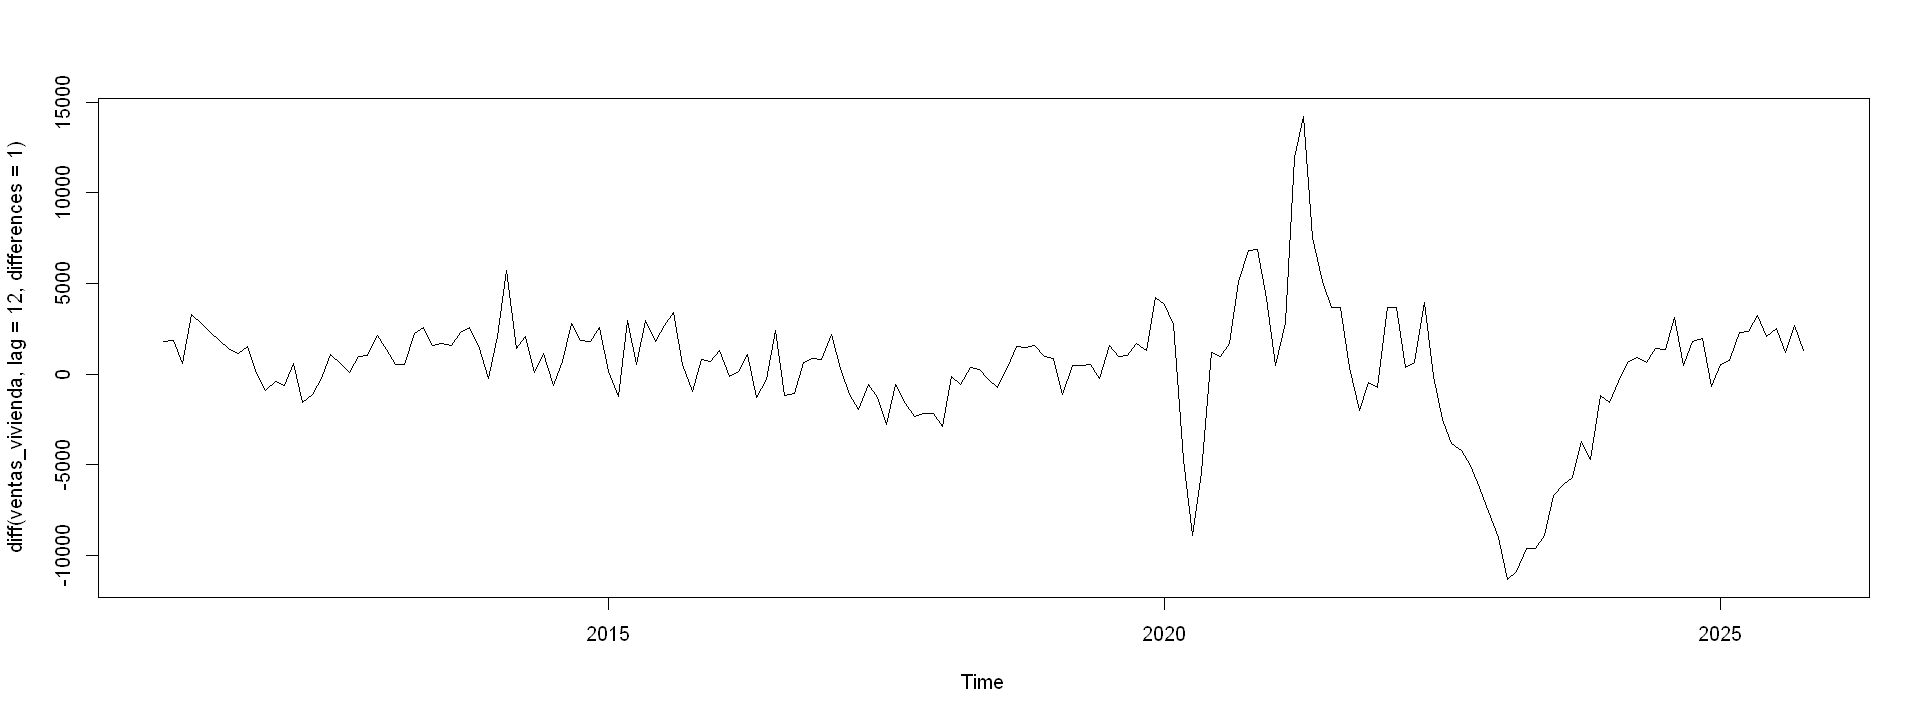

In [27]:
#el lag me permite hacerlo estacional
plot(diff(ventas_vivienda, lag=12, differences=1))

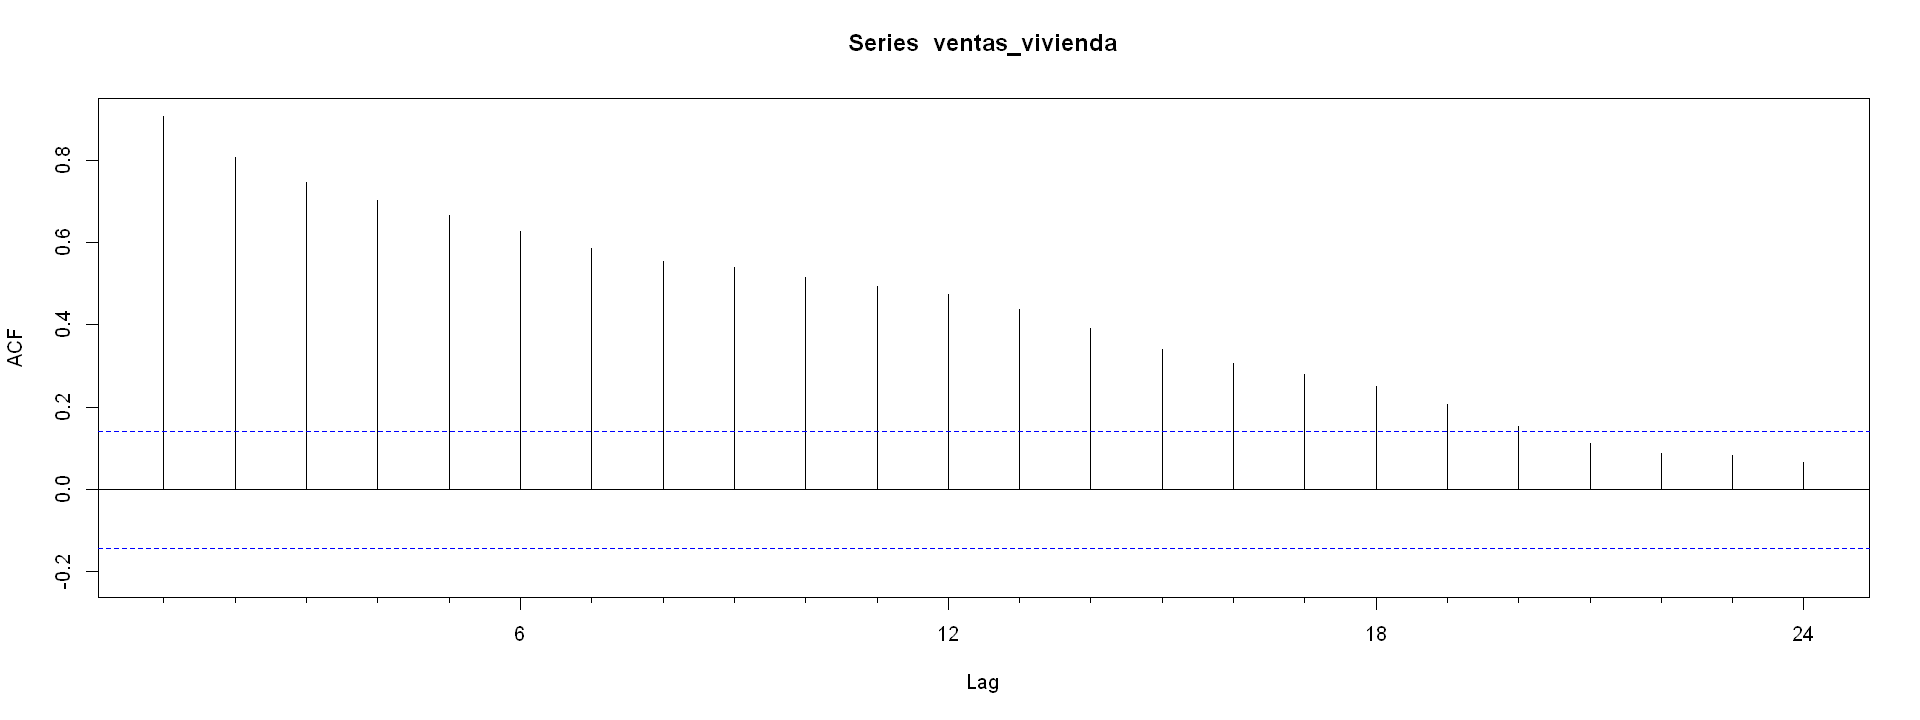

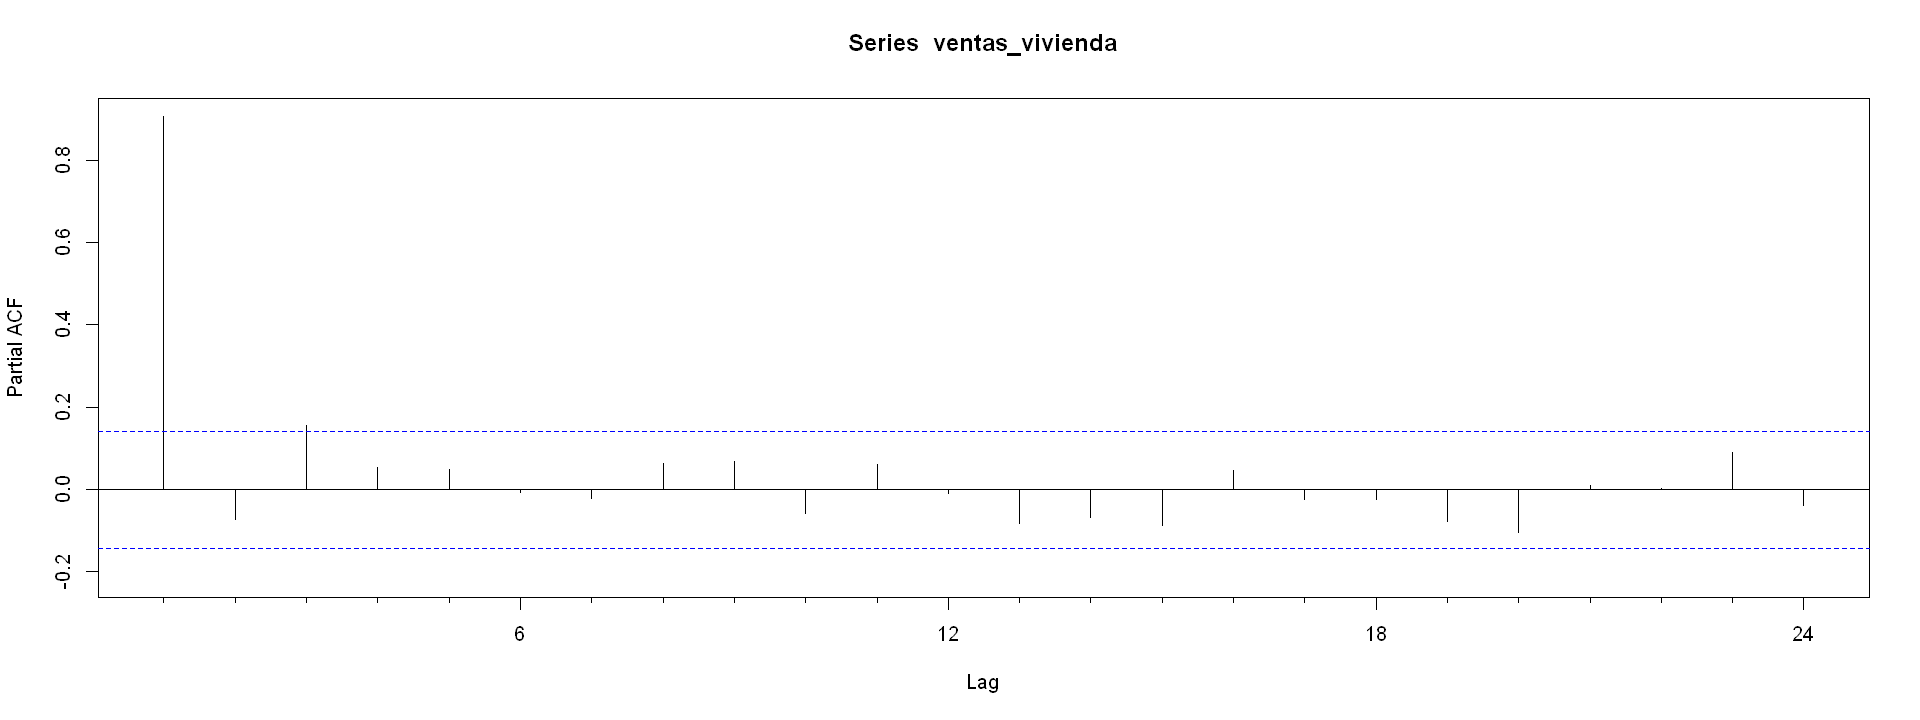

In [30]:
# Veamos autocorrelaciones
Acf(ventas_vivienda)
Pacf(ventas_vivienda)

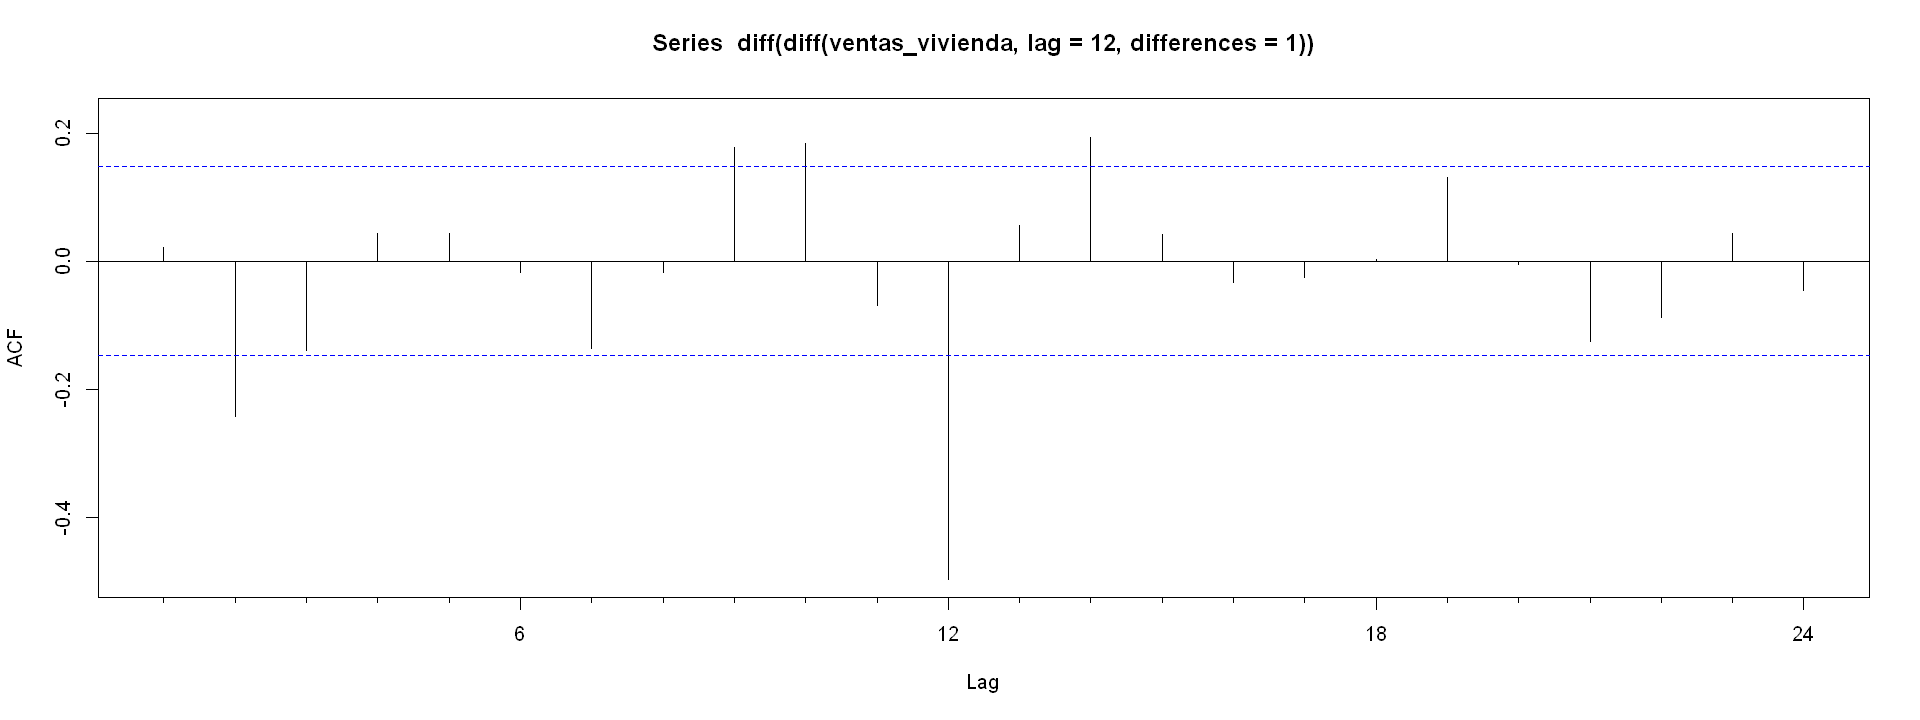

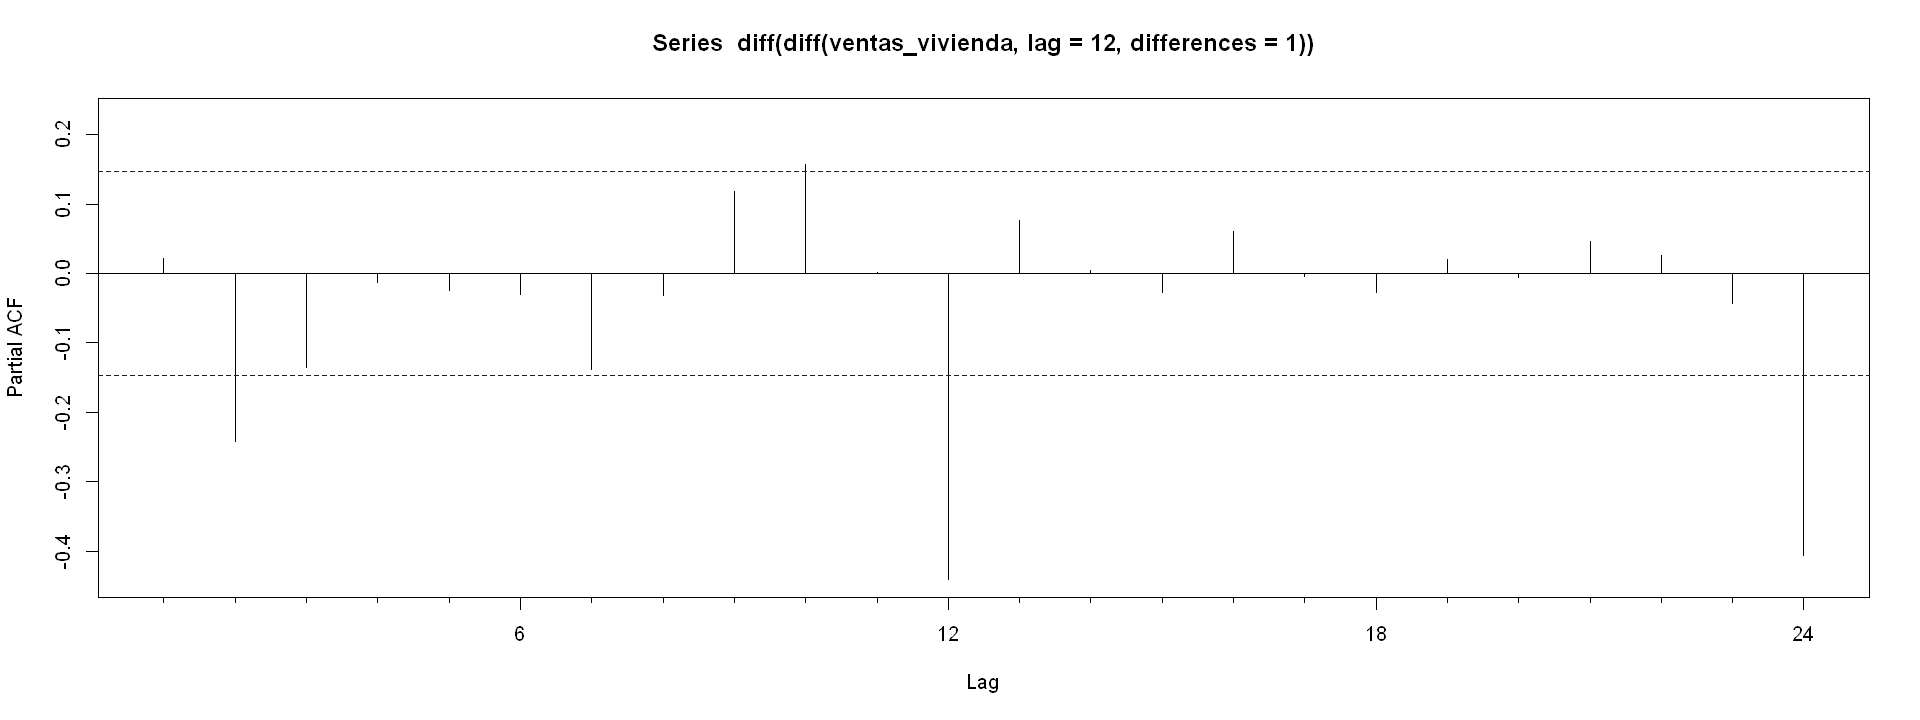

In [39]:
# eliminando el efecto estacional
Acf(diff(diff(ventas_vivienda, lag=12, differences=1)))
Pacf(diff(diff(ventas_vivienda, lag=12, differences=1)))

### Outliers

In [35]:
result<-tso(ventas_vivienda)
#estos son los outliers
result$outliers

type,ind,time,coefhat,tstat
<fct>,<int>,<chr>,<dbl>,<dbl>
AO,50,2014:02,3834.398,4.195910
TC,123,2020:03,-7816.652,-6.434199
LS,126,2020:06,4585.437,3.924515
AO,137,2021:05,-3454.801,-3.761670


In [36]:
result$fit$coef
?tso
result$fit$
result$fit$arma


ma1          sma1          AO50         TC123         LS126 
   -0.2304764     0.1900333  3834.3977939 -7816.6516490  4585.4366718 
        AO137 
-3454.8010395

NULL

tso                 package:tsoutliers                 R Documentation

_A_u_t_o_m_a_t_i_c _P_r_o_c_e_d_u_r_e _f_o_r _D_e_t_e_c_t_i_o_n _o_f _O_u_t_l_i_e_r_s

_D_e_s_c_r_i_p_t_i_o_n:

     These functions are the interface to the automatic detection
     procedure provided in this package.

_U_s_a_g_e:

     tso(y, xreg = NULL, cval = NULL, delta = 0.7, 
       types = c("AO", "LS", "TC"), 
       maxit = 1, maxit.iloop = 4, maxit.oloop = 4, cval.reduce = 0.14286, 
       discard.method = c("en-masse", "bottom-up"), discard.cval = NULL, 
       remove.method, remove.cval,
       tsmethod = c("auto.arima", "arima"), 
       args.tsmethod = NULL, logfile = NULL, check.rank = FALSE)
     
     tso0(x, xreg = NULL, cval = 3.5, delta = 0.7, 
       types = c("AO", "LS", "TC"), maxit.iloop = 4, maxit.oloop = 4,
       discard.method = c("en-masse", "bottom-up"), discard.cval = NULL,   
       tsmethod = c("auto.arima", "arima"), args.ts

## Modelos

### Suavización exponenciall

In [ ]:
#modelo suavización exponencial
modelo1<-ets(ventas_vivienda, model="ZZZ",opt.crit="mse",ic="aic")
summary(modelo1)

ETS(A,N,A) 

Call:
ets(y = ventas_vivienda, model = "ZZZ", opt.crit = "mse", ic = "aic")

  Smoothing parameters:
    alpha = 0.9999 
    gamma = 1e-04 

  Initial states:
    l = 10966.7686 
    s = -1038.743 34.7636 329.6502 422.2095 600.0132 116.4613
           -537.0566 -787.4887 -421.2635 150.9975 859.2741 271.1827

  sigma:  1371.427

     AIC     AICc      BIC 
3757.363 3760.121 3806.068 

Training set error measures:
                   ME     RMSE      MAE        MPE     MAPE      MASE
Training set 22.04164 1319.934 922.7159 -0.3106267 6.692445 0.3958579
                   ACF1
Training set 0.03565753

### ARIMAX

In [40]:
#Tengo que leer de nuevo el df con las variables Dummy 
#Lectura de datos
ventas<-read_xlsx('Time-series-datos.xlsx')